<a href="https://colab.research.google.com/github/trialdyk/marchine-learning/blob/main/JS07/JS07_Tugas_Praktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum Pembelajaran Mesin - JS07 Klasterisasi
## Tugas Praktikum: Klasterisasi Data Nasabah Kartu Kredit

Praktikum ini menganalisis dataset *CC_Customer_Dataset.csv* dengan algoritma K-Means dan DBSCAN untuk segmentasi nasabah.

### Langkah 0 - Load Dataset



In [1]:
# Download dataset nasabah kartu kredit
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('CC_Customer_Dataset.csv')
print(df.info())
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB
None


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


### Soal 1
Buatlah scatterplot berdasarkan dataset menggunakan dua variabel, yaitu `Avg_Credit_Limit` dan `Total_Credit_Cards`. Apakah sebaran data dapat dikatakan linier?

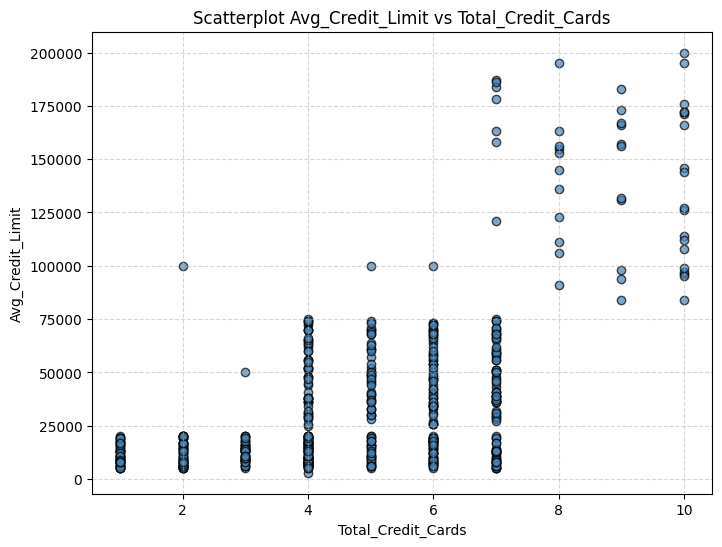

In [2]:
# 1. Scatterplot Avg_Credit_Limit vs Total_Credit_Cards
plt.figure(figsize=(8, 6))
plt.scatter(df['Total_Credit_Cards'], df['Avg_Credit_Limit'], color='steelblue', alpha=0.7, edgecolors='k')
plt.xlabel('Total_Credit_Cards')
plt.ylabel('Avg_Credit_Limit')
plt.title('Scatterplot Avg_Credit_Limit vs Total_Credit_Cards')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Analisis Soal 1:**
Berdasarkan scatterplot di atas, sebaran data **tidak dapat dikatakan linier**. Titik-titik data terdistribusi mengelompok di beberapa area terpisah (cluster densitas) daripada membentuk garis lurus diagonal. Terlihat setidaknya 3 kelompok konsentrasi data yang jelas:
1. Nasabah dengan limit kredit rendah dan jumlah kartu kredit sedikit (1-4 kartu).
2. Nasabah dengan limit kredit menengah dan jumlah kartu sedang (4-7 kartu).
3. Nasabah premium dengan limit kredit sangat tinggi dan jumlah kartu banyak (6-10 kartu).

### Soal 2
Buatlah model klasterisasi dengan menggunakan model K-Means. Tentukan jumlah $k$ yang terbaik dengan menggunakan ***elbow method***. Lengkapi analisis Anda dengan *linechart* dan hasil analisis mengapa Anda memilih nilai tersebut.

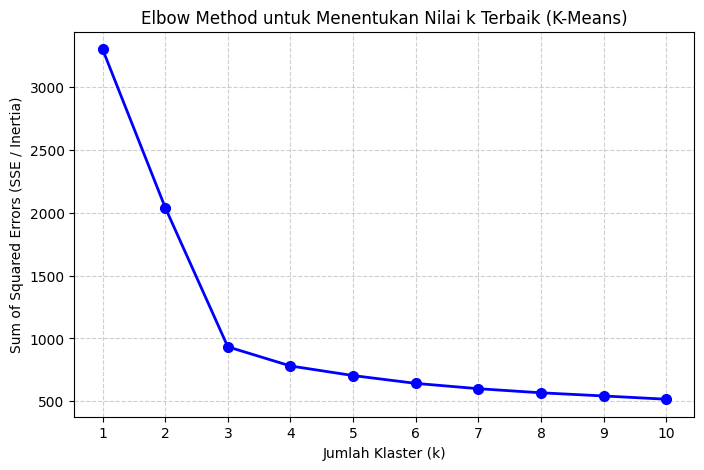

In [3]:
# Seleksi fitur numerik untuk klasterisasi (mengabaikan identifier Sl_No dan Customer Key)
features = ['Avg_Credit_Limit', 'Total_Credit_Cards', 'Total_visits_bank', 'Total_visits_online', 'Total_calls_made']
X_cc = df[features]

# Standarisasi fitur agar skala variabel limit (puluhan ribu) seimbang dengan jumlah kunjungan (satuan)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_cc_scaled = scaler.fit_transform(X_cc)

# Elbow Method untuk K-Means
from sklearn.cluster import KMeans

sse_cc = []
K_range = range(1, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cc_scaled)
    sse_cc.append(km.inertia_)

# Plotting Elbow Method
plt.figure(figsize=(8, 5))
plt.plot(K_range, sse_cc, 'bo-', linewidth=2, markersize=7)
plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('Sum of Squared Errors (SSE / Inertia)')
plt.title('Elbow Method untuk Menentukan Nilai k Terbaik (K-Means)')
plt.xticks(K_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Analisis Soal 2:**
Berdasarkan grafik *Elbow Method* di atas:
- Terjadi penurunan SSE yang sangat curam dari $k=1$ ke $k=2$ dan $k=2$ ke $k=3$.
- Pada titik **$k=3$**, terbentuk sudut 'siku' (*elbow point*) di mana setelah $k=3$, laju penurunan SSE mulai melandai secara konsisten dan stabil.
- Oleh karena itu, jumlah klaster optimal yang dipilih adalah **$k = 3$**.

### Soal 3
Gambarkan hasil klasterisasi dengan model K-Means dengan menggunakan scatterplot.

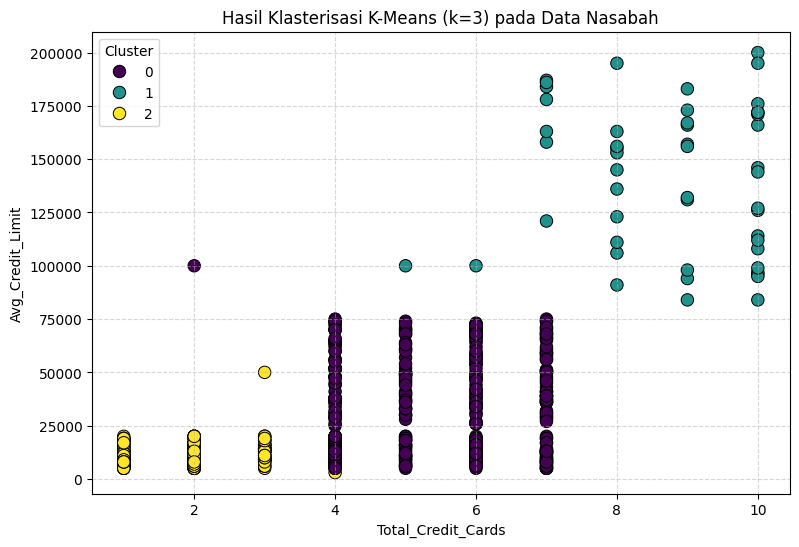

In [4]:
# Pelatihan model K-Means dengan k=3
kmeans_best = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters_km = kmeans_best.fit_predict(X_cc_scaled)

# Visualisasi hasil klasterisasi K-Means
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=df['Total_Credit_Cards'],
    y=df['Avg_Credit_Limit'],
    hue=clusters_km,
    palette='viridis',
    s=80,
    edgecolor='k'
)
plt.xlabel('Total_Credit_Cards')
plt.ylabel('Avg_Credit_Limit')
plt.title('Hasil Klasterisasi K-Means (k=3) pada Data Nasabah')
plt.legend(title='Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Soal 4
Buatlah model klasterisasi dengan menggunakan DBSCAN **dengan seluruh variabel yang dapat digunakan**.

In [5]:
# Soal 4: Klasterisasi DBSCAN dengan seluruh variabel numerik
from sklearn.cluster import DBSCAN

# Menggunakan data yang telah distandarisasi (X_cc_scaled)
# Parameter default yang representatif untuk data berskala (eps=0.8, min_samples=5)
dbscan_model = DBSCAN(eps=0.8, min_samples=5)
clusters_db = dbscan_model.fit_predict(X_cc_scaled)

# Ringkasan hasil klasterisasi DBSCAN
unique_labels, counts = np.unique(clusters_db, return_counts=True)
print("Distribusi Klaster DBSCAN:")
for lbl, count in zip(unique_labels, counts):
    label_name = f"Noise (Outlier)" if lbl == -1 else f"Cluster {lbl}"
    print(f"- {label_name}: {count} data")

Distribusi Klaster DBSCAN:
- Noise (Outlier): 44 data
- Cluster 0: 606 data
- Cluster 1: 10 data


### Soal 5
Tentukan parameter $k$ / $\varepsilon$ yang terbaik dengan menggunakan ***k-distance graph*** (Elbow Method pada DBSCAN). Lengkapi analisis Anda dengan linechart dan hasil analisis.

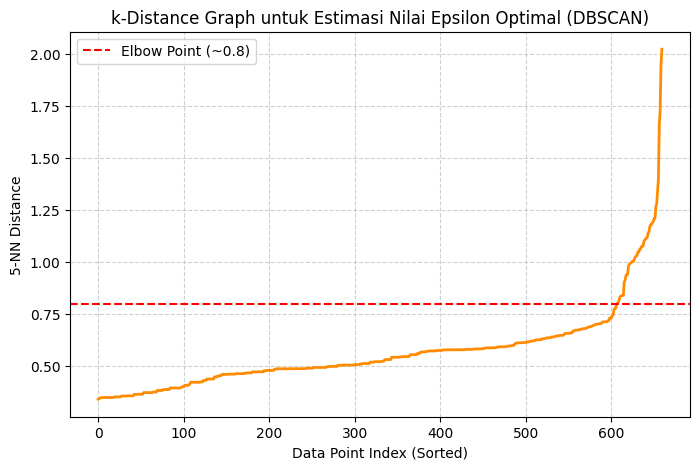

In [6]:
# Soal 5: Menentukan parameter epsilon optimal menggunakan k-distance graph (Elbow pada DBSCAN)
from sklearn.neighbors import NearestNeighbors

# Untuk min_samples = 5, kita mencari jarak ke tetangga ke-5 (k=5)
k_neighbors = 5
neighbors = NearestNeighbors(n_neighbors=k_neighbors)
neighbors_fit = neighbors.fit(X_cc_scaled)
distances, indices = neighbors_fit.kneighbors(X_cc_scaled)

# Urutkan jarak tetangga ke-k dari terkecil ke terbesar
sorted_distances = np.sort(distances[:, k_neighbors - 1])

# Plot k-distance graph
plt.figure(figsize=(8, 5))
plt.plot(sorted_distances, color='darkorange', linewidth=2)
plt.xlabel('Data Point Index (Sorted)')
plt.ylabel(f'{k_neighbors}-NN Distance')
plt.title('k-Distance Graph untuk Estimasi Nilai Epsilon Optimal (DBSCAN)')
plt.axhline(y=0.8, color='red', linestyle='--', label='Elbow Point (~0.8)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

**Analisis Soal 5:**
Pada grafik *k-distance graph* di atas, kurva menunjukkan perubahan kemiringan tajam (*elbow point*) di sekitar nilai jarak **$\varepsilon \approx 0.75 - 0.85$**.
- Nilai epsilon di bawah 0.7 menyebabkan terlalu banyak data dianggap sebagai *noise* (-1).
- Nilai epsilon di atas 1.0 menyebabkan beberapa klaster saling melebur menjadi satu.
- Dengan demikian, parameter **`eps = 0.8`** dan **`min_samples = 5`** merupakan kombinasi yang seimbang.

### Soal 6
Tentukan nilai *silhouette score* dan DBI dari model DBSCAN.

In [7]:
# Soal 6: Evaluasi Silhouette Score dan Davies-Bouldin Index (DBI) pada DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Filter data noise (-1) sebelum menghitung skor metrik jika diperlukan,
# atau evaluasi pada data valid yang terklaster
mask = clusters_db != -1
X_valid = X_cc_scaled[mask]
clusters_valid = clusters_db[mask]

# Menghitung metrik evaluasi
sil_score = silhouette_score(X_valid, clusters_valid)
dbi_score = davies_bouldin_score(X_valid, clusters_valid)

print(f"Evaluasi Klasterisasi DBSCAN (tanpa noise):")
print(f"- Silhouette Score: {sil_score:.4f}")
print(f"- Davies-Bouldin Index (DBI): {dbi_score:.4f}")

# Evaluasi keseluruhan termasuk noise
sil_total = silhouette_score(X_cc_scaled, clusters_db)
dbi_total = davies_bouldin_score(X_cc_scaled, clusters_db)
print(f"\nEvaluasi Klasterisasi DBSCAN (termasuk noise):")
print(f"- Silhouette Score: {sil_total:.4f}")
print(f"- Davies-Bouldin Index (DBI): {dbi_total:.4f}")

Evaluasi Klasterisasi DBSCAN (tanpa noise):
- Silhouette Score: 0.5445
- Davies-Bouldin Index (DBI): 0.5154

Evaluasi Klasterisasi DBSCAN (termasuk noise):
- Silhouette Score: 0.4895
- Davies-Bouldin Index (DBI): 2.0349
